In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, skew
import sklearn
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
%matplotlib inline
import random
# sklearn modules for data preprocessing-------------------------------------

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 

#sklearn modules for Model Selection--------------------------------------

from sklearn import svm, tree, linear_model, neighbors
from sklearn import naive_bayes, ensemble, discriminant_analysis, gaussian_process
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

#sklearn modules for Model Evaluation & Improvement---------------------------
    
from sklearn.metrics import confusion_matrix, accuracy_score 
from sklearn.metrics import f1_score, precision_score, recall_score, fbeta_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold

from sklearn import feature_selection
from sklearn import model_selection
from sklearn import metrics

from sklearn.metrics import classification_report, precision_recall_curve
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.metrics import make_scorer, recall_score, log_loss
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import MinMaxScaler


In [2]:
#https://www.kaggle.com/datasets/nelgiriyewithana/credit-card-fraud-detection-dataset-2023
dataset = pd.read_csv('creditcard_2023.csv')

In [3]:
dataset.head()

,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0


In [4]:
dataset.describe()

,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,568630.000000,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,...,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,568630.000000,568630.0
mean,284314.500000,-1.109271e-14,-3.429498e-14,-1.209242e-14,3.825991e-15,6.288281e-15,-2.751174e-14,1.240002e-14,8.208047e-15,-1.002980e-14,...,2.210679e-15,-8.767441e-16,4.376179e-16,6.825608e-16,2.545689e-15,1.781906e-15,2.817586e-15,2.891419e-15,12041.957635,0.5
std,164149.486121,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,...,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,6919.644449,0.5
min,0.000000,-3.495584e+00,-4.996657e+01,-3.183760e+00,-4.951222e+00,-9.952786e+00,-2.111111e+01,-4.351839e+00,-1.075634e+01,-3.751919e+00,...,-1.938252e+01,-7.734798e+00,-3.029545e+01,-4.067968e+00,-1.361263e+01,-8.226969e+00,-1.049863e+01,-3.903524e+01,50.010000,0.0
25%,142157.250000,-5.652859e-01,-4.866777e-01,-6.492987e-01,-6.560203e-01,-2.934955e-01,-4.458712e-01,-2.835329e-01,-1.922572e-01,-5.687446e-01,...,-1.664408e-01,-4.904892e-01,-2.376289e-01,-6.515801e-01,-5.541485e-01,-6.318948e-01,-3.049607e-01,-2.318783e-01,6054.892500,0.0
50%,284314.500000,-9.363846e-02,-1.358939e-01,3.528579e-04,-7.376152e-02,8.108788e-02,7.871758e-02,2.333659e-01,-1.145242e-01,9.252647e-02,...,-3.743065e-02,-2.732881e-02,-5.968903e-02,1.590123e-02,-8.193162e-03,-1.189208e-02,-1.729111e-01,-1.392973e-02,12030.150000,0.5
75%,426471.750000,8.326582e-01,3.435552e-01,6.285380e-01,7.070047e-01,4.397368e-01,4.977881e-01,5.259548e-01,4.729905e-02,5.592621e-01,...,1.479787e-01,4.638817e-01,1.557153e-01,7.007374e-01,5.500147e-01,6.728879e-01,3.340230e-01,4.095903e-01,18036.330000,1.0
max,568629.000000,2.229046e+00,4.361865e+00,1.412583e+01,3.201536e+00,4.271689e+01,2.616840e+01,2.178730e+02,5.958040e+00,2.027006e+01,...,8.087080e+00,1.263251e+01,3.170763e+01,1.296564e+01,1.462151e+01,5.623285e+00,1.132311e+02,7.725594e+01,24039.930000,1.0


In [5]:
dataset.columns.to_series().groupby(dataset.dtypes).groups

{int64: ['id', 'Class'], float64: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']}

In [6]:
# for each object column, calculate value counts and share of nulls

for col in dataset :
    print(f"Column: {col}")

    # count for each value
    print(dataset[col].value_counts())



    # share of null values
    null_share = dataset[col].isnull().mean() * 100
    print("Share of null values: %.2f%%" % null_share)

    print("\n---\n")


Column: id
0         1
379089    1
379083    1
379084    1
379085    1
         ..
189537    1
189536    1
189535    1
189534    1
568629    1
Name: id, Length: 568630, dtype: int64
Share of null values: 0.00%

---

Column: V1
-1.704517    3539
-2.459141    1399
-1.161336     259
-1.065576     255
-1.522526     246
             ... 
-0.272852       1
 1.822123       1
 0.556931       1
 0.276802       1
-0.795144       1
Name: V1, Length: 552035, dtype: int64
Share of null values: 0.00%

---

Column: V2
 2.599199    3539
 3.326970    1399
 0.528310     259
 1.399009     255
 1.314583     246
             ... 
 0.015921       1
-0.901321       1
-0.192861       1
-0.095077       1
 0.433236       1
Name: V2, Length: 552035, dtype: int64
Share of null values: 0.00%

---

Column: V3
-1.205391    3539
-2.476251    1399
-1.169483     259
-1.471620     255
-1.741485     246
             ... 
 0.032879       1
 0.038569       1
-0.276581       1
 0.324786       1
-0.649140       1
Name: V3, L

In [7]:
# for memory efficiency , convert data to int32
dataset=dataset.astype('int32')


Column: id
Mean: 284314.5
Sigma: 164149.4861214325
Median: 284314.5
Min: 0
Max: 568629
Q1: 142157.25
Q3: 426471.75
Missing Value Ratio: 0.0%




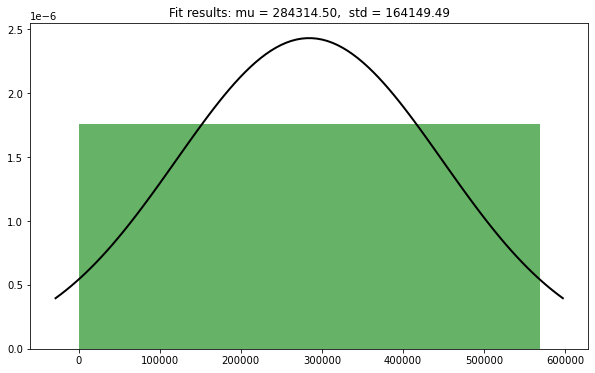

Column: V1
Mean: 0.01578706716142307
Sigma: 0.6443663140296252
Median: 0.0
Min: -3
Max: 2
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




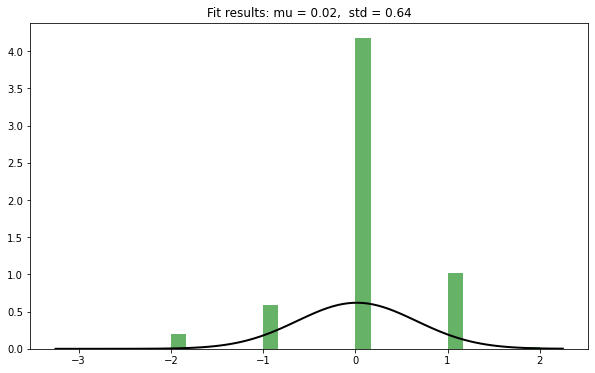

Column: V2
Mean: 0.08398431317376853
Sigma: 0.7576165019673943
Median: 0.0
Min: -49
Max: 4
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




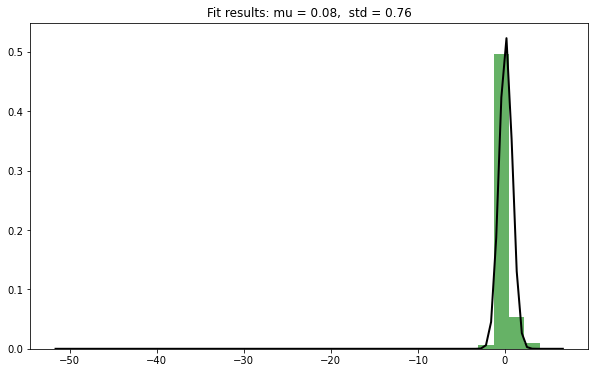

Column: V3
Mean: 0.006272971879781228
Sigma: 0.6976526007602919
Median: 0.0
Min: -3
Max: 14
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




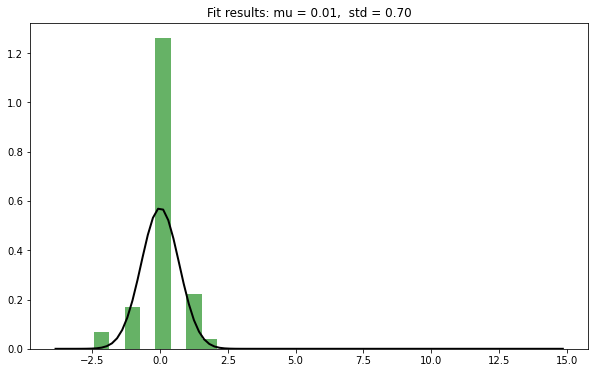

Column: V4
Mean: 0.027692875859522008
Sigma: 0.6936942315250554
Median: 0.0
Min: -4
Max: 3
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




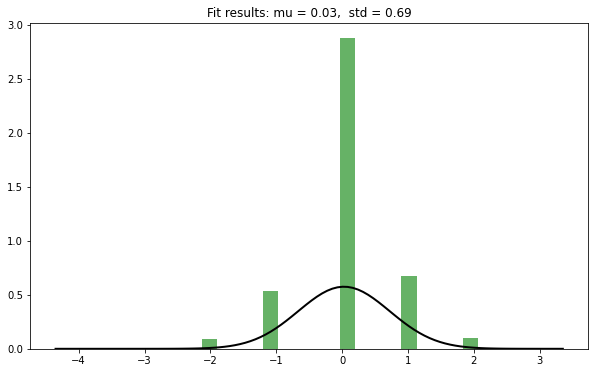

Column: V5
Mean: -0.04755640750575946
Sigma: 0.7505322814711692
Median: 0.0
Min: -9
Max: 42
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




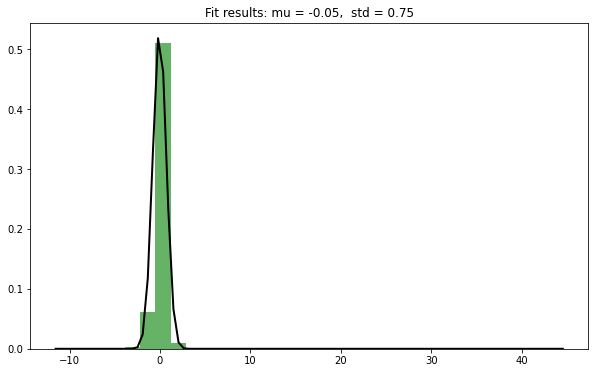

Column: V6
Mean: -0.03392188241914778
Sigma: 0.7314948428769206
Median: 0.0
Min: -21
Max: 26
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




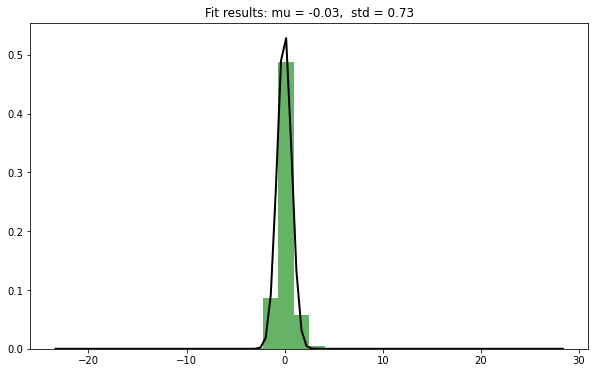

Column: V7
Mean: -0.1312171359231838
Sigma: 0.7486030052226073
Median: 0.0
Min: -4
Max: 217
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




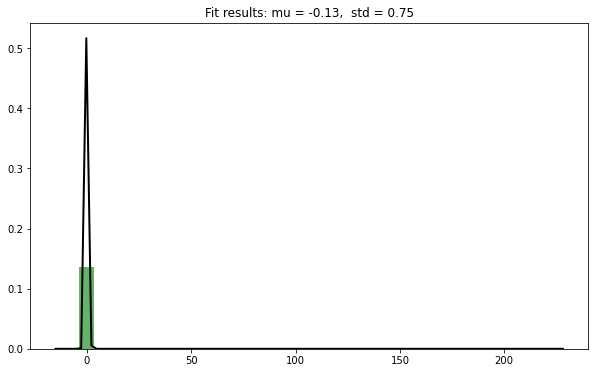

Column: V8
Mean: 0.046233930675483176
Sigma: 0.8667061838562213
Median: 0.0
Min: -10
Max: 5
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




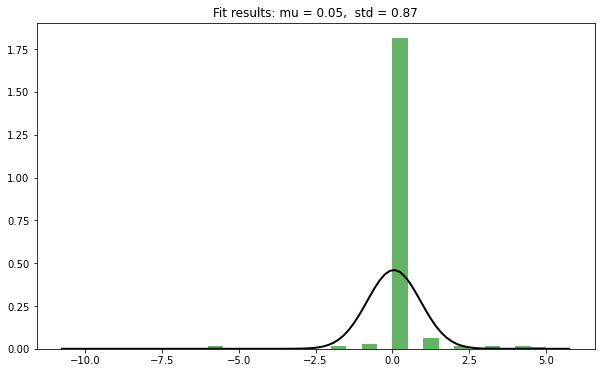

Column: V9
Mean: -0.0372878673302499
Sigma: 0.7043231150951779
Median: 0.0
Min: -3
Max: 20
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




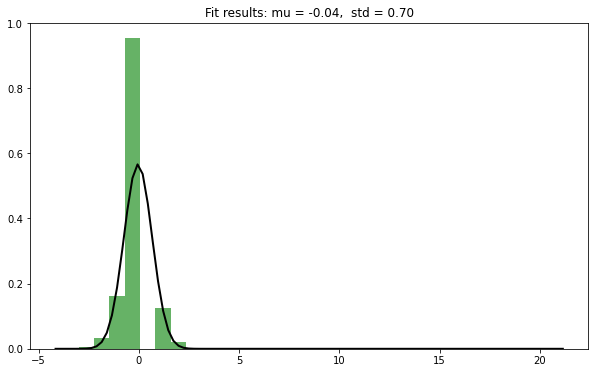

Column: V10
Mean: -0.06336106079524471
Sigma: 0.6847293787568165
Median: 0.0
Min: -3
Max: 31
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




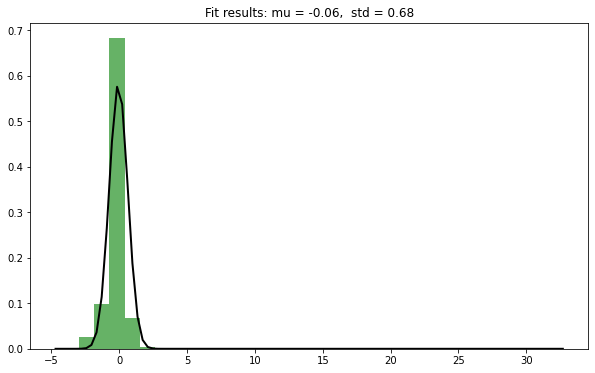

Column: V11
Mean: 0.005325079577229481
Sigma: 0.6814361855558851
Median: 0.0
Min: -5
Max: 2
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




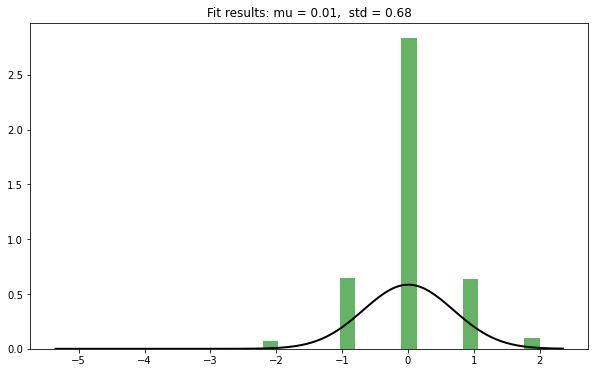

Column: V12
Mean: -0.014689692770342754
Sigma: 0.6379824609000617
Median: 0.0
Min: -2
Max: 17
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




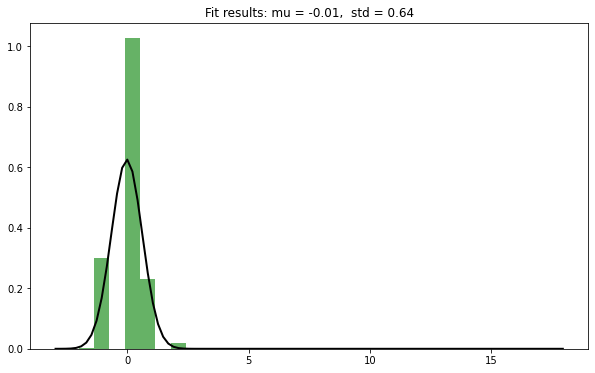

Column: V13
Mean: -0.007848688954152964
Sigma: 0.6771413114215915
Median: 0.0
Min: -5
Max: 7
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




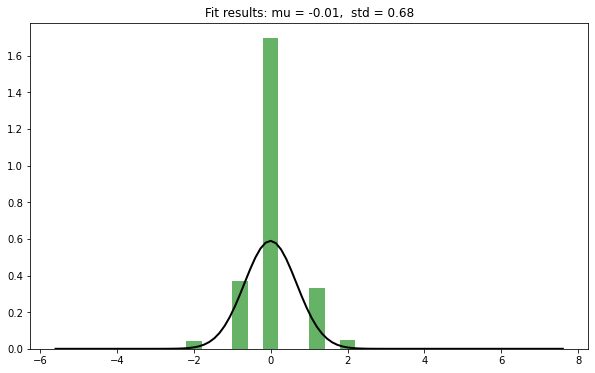

Column: V14
Mean: -0.05106484005416528
Sigma: 0.6532957830723424
Median: 0.0
Min: -2
Max: 19
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




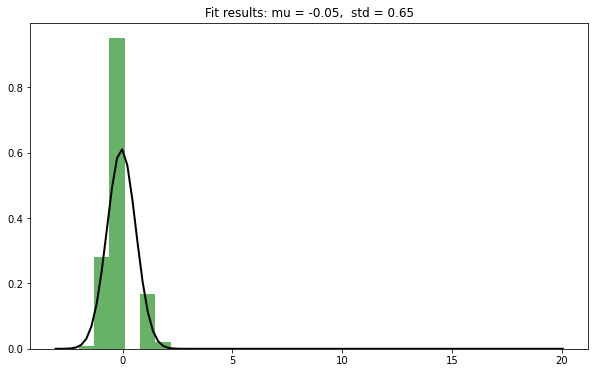

Column: V15
Mean: 0.007389691011729947
Sigma: 0.6975950294935553
Median: 0.0
Min: -3
Max: 14
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




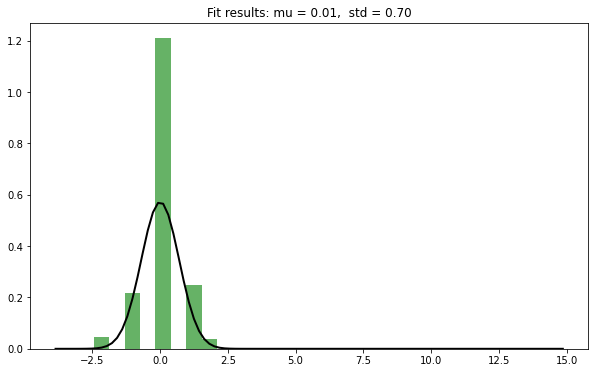

Column: V16
Mean: -0.04836361078381373
Sigma: 0.6820179950766933
Median: 0.0
Min: -2
Max: 46
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




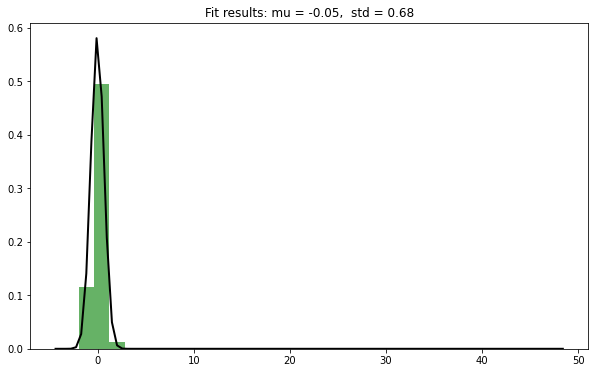

Column: V17
Mean: -0.10019520602149025
Sigma: 0.7147418399954251
Median: 0.0
Min: -2
Max: 6
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




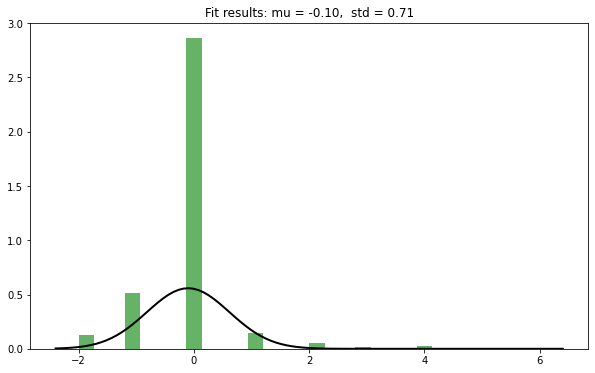

Column: V18
Mean: -0.04184970894958057
Sigma: 0.7098231548151196
Median: 0.0
Min: -2
Max: 6
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




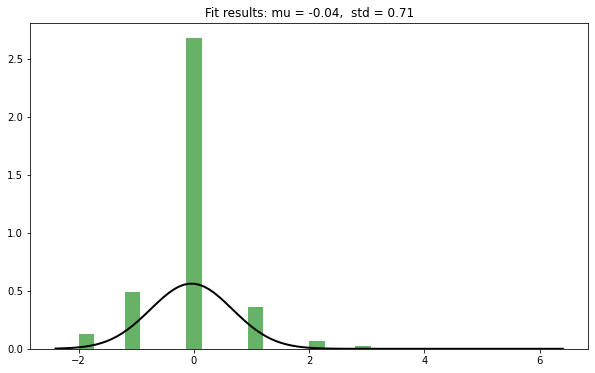

Column: V19
Mean: 0.004934667534248985
Sigma: 0.7018465522666157
Median: 0.0
Min: -7
Max: 3
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




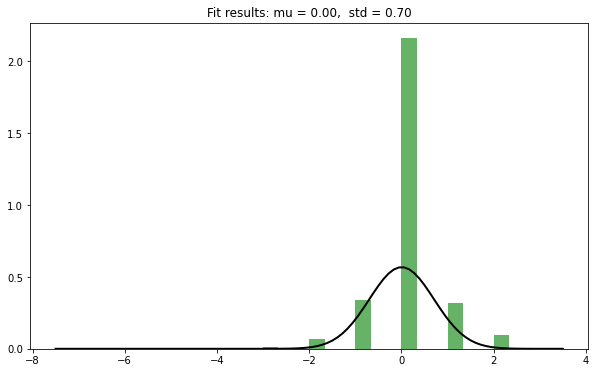

Column: V20
Mean: 0.051356769779997535
Sigma: 0.8163837415147809
Median: 0.0
Min: -78
Max: 29
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




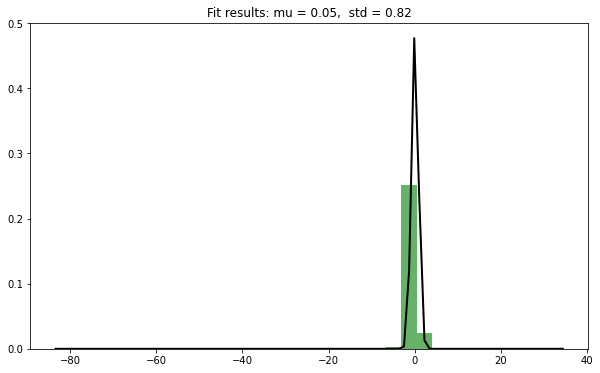

Column: V21
Mean: -0.021370662821166665
Sigma: 0.9121836958575759
Median: 0.0
Min: -19
Max: 8
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




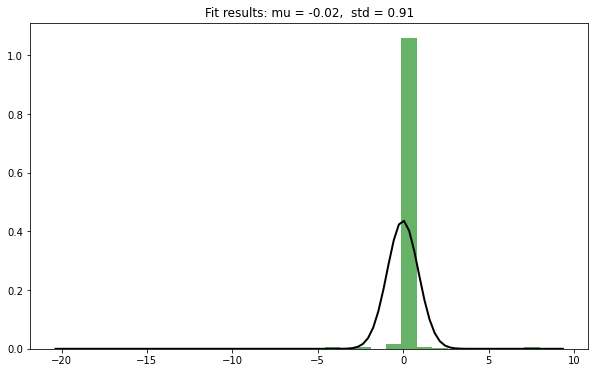

Column: V22
Mean: 0.019059845593795616
Sigma: 0.7762432363494858
Median: 0.0
Min: -7
Max: 12
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




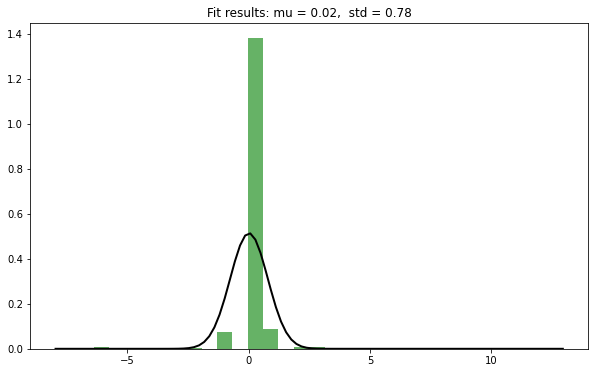

Column: V23
Mean: 0.03565763325888539
Sigma: 0.8603342739143479
Median: 0.0
Min: -30
Max: 31
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




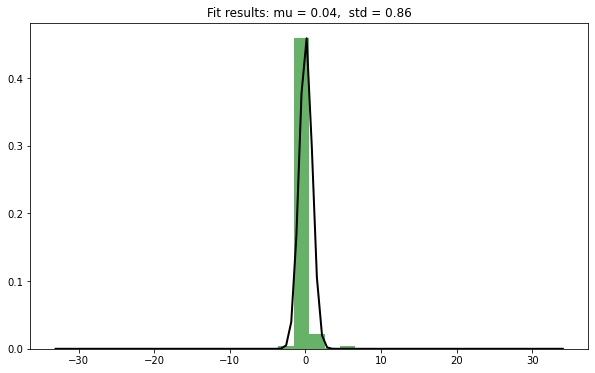

Column: V24
Mean: 0.012322599933172713
Sigma: 0.6887147440315762
Median: 0.0
Min: -4
Max: 12
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




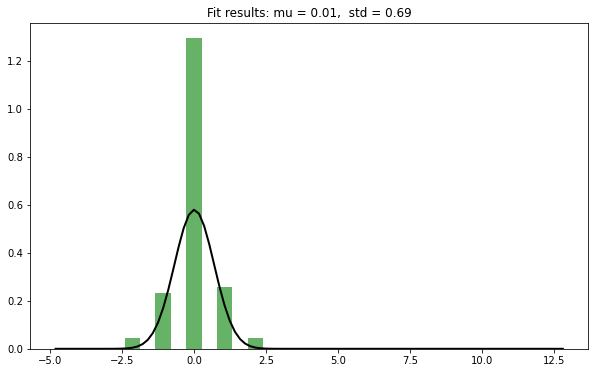

Column: V25
Mean: 0.0010498918453124176
Sigma: 0.7145042337950717
Median: 0.0
Min: -13
Max: 14
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




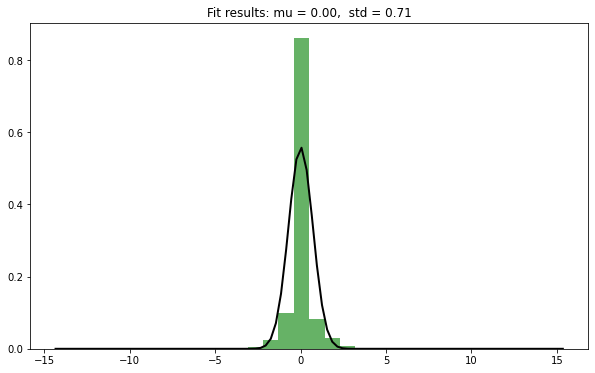

Column: V26
Mean: 0.021154353446001795
Sigma: 0.6961131241570284
Median: 0.0
Min: -8
Max: 5
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




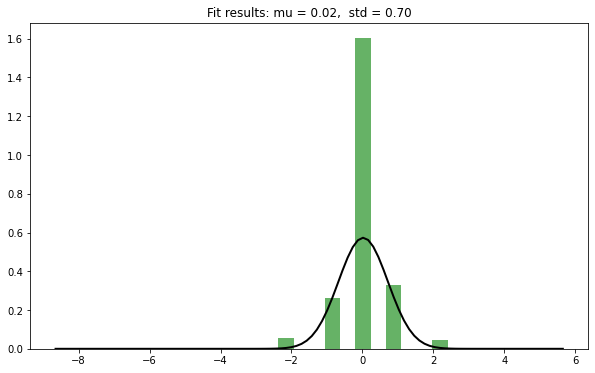

Column: V27
Mean: 0.04282925628264425
Sigma: 0.7717962633823524
Median: 0.0
Min: -10
Max: 113
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




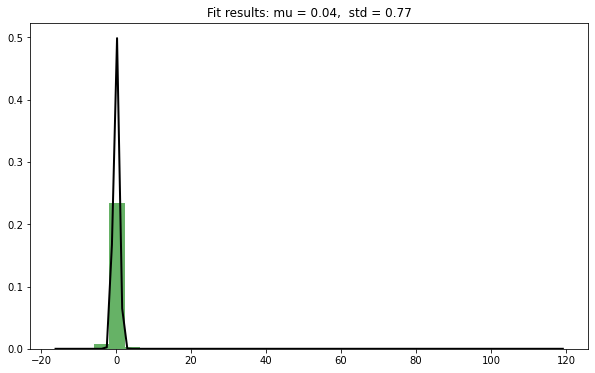

Column: V28
Mean: -0.0400225102439196
Sigma: 0.7872211842603569
Median: 0.0
Min: -39
Max: 77
Q1: 0.0
Q3: 0.0
Missing Value Ratio: 0.0%




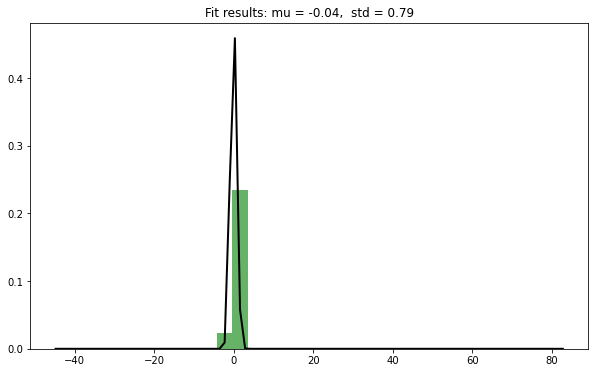

Column: Amount
Mean: 12041.461816998752
Sigma: 6919.644122181139
Median: 12030.0
Min: 50
Max: 24039
Q1: 6054.0
Q3: 18036.0
Missing Value Ratio: 0.0%




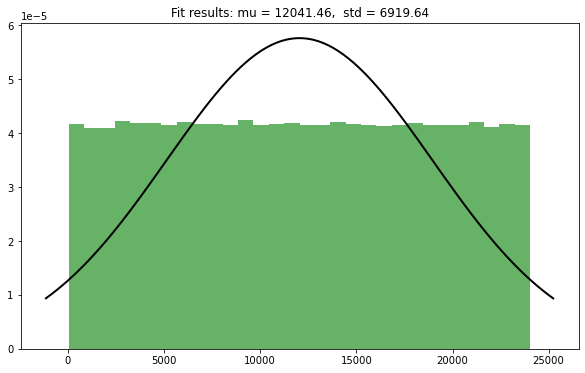

Column: Class
Mean: 0.5
Sigma: 0.5000004396537814
Median: 0.5
Min: 0
Max: 1
Q1: 0.0
Q3: 1.0
Missing Value Ratio: 0.0%




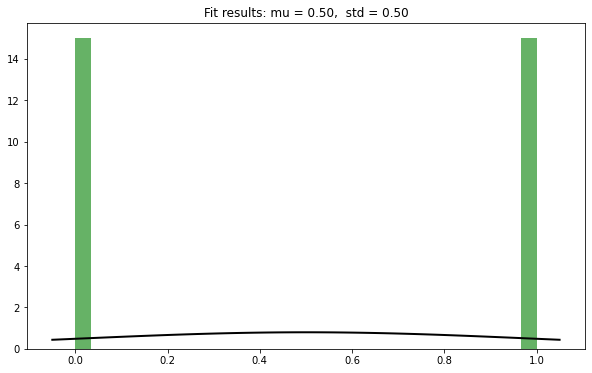

In [8]:
# Iterate over each column
for column in dataset:
    # Calculate statistics
    mean = dataset[column].mean()
    sigma = dataset[column].std()
    median = dataset[column].median()
    minimum = dataset[column].min()
    maximum = dataset[column].max()
    Q1 = dataset[column].quantile(0.25)
    Q3 = dataset[column].quantile(0.75)

    # Calculate the ratio of missing values
    missing_ratio = dataset[column].isnull().mean() * 100

    # Print statistics
    print(f"Column: {column}")
    print(f"Mean: {mean}")
    print(f"Sigma: {sigma}")
    print(f"Median: {median}")
    print(f"Min: {minimum}")
    print(f"Max: {maximum}")    
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"Missing Value Ratio: {missing_ratio}%")
    print("\n")

    # Plot histogram
    plt.figure(figsize=(10,6))
    plt.hist(dataset[column], bins=30, density=True, alpha=0.6, color='g')
    
    # Plot normal distribution with same mean and standard deviation
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mean, sigma)
    plt.plot(x, p, 'k', linewidth=2)

    title = f"Fit results: mu = {mean:.2f},  std = {sigma:.2f}"
    plt.title(title)

    plt.show()


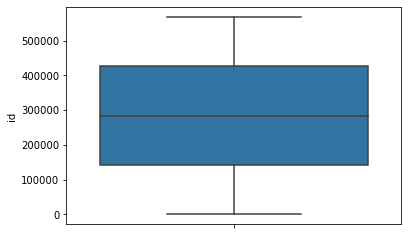

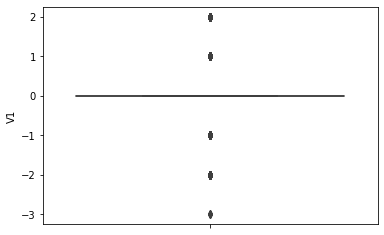

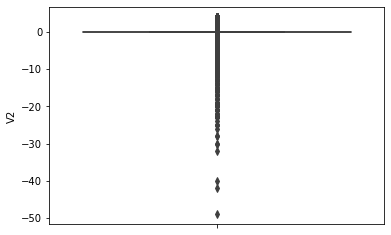

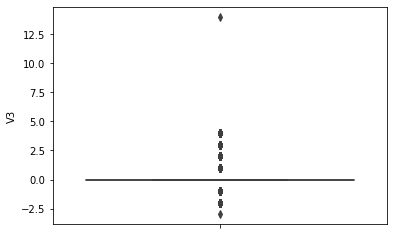

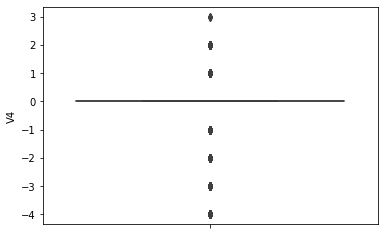

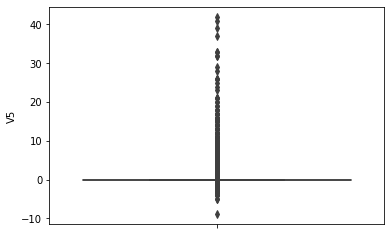

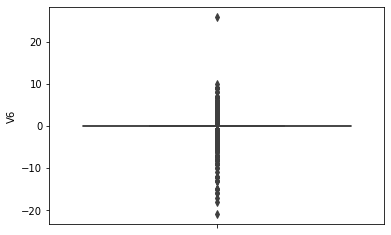

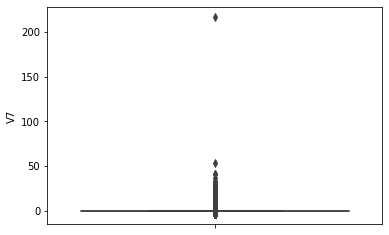

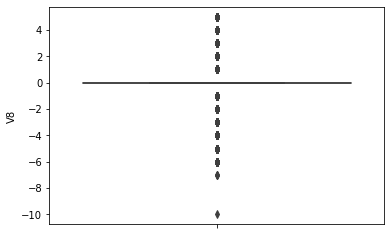

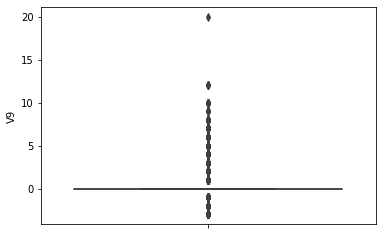

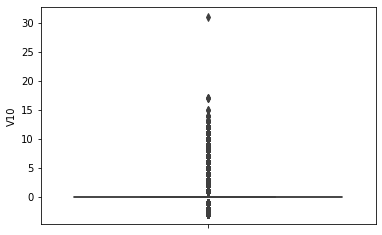

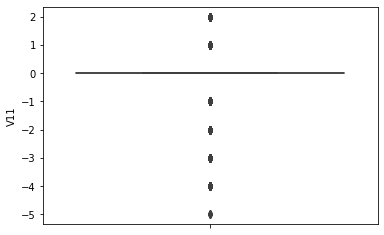

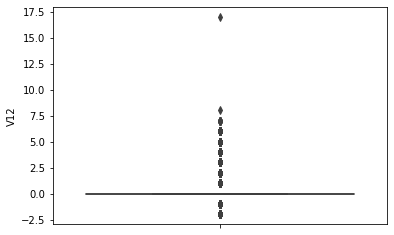

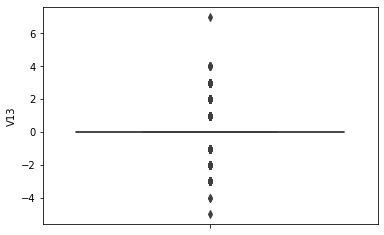

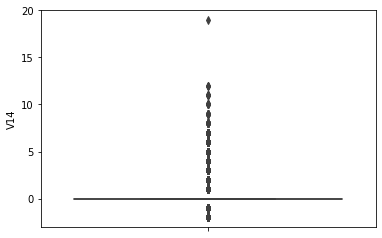

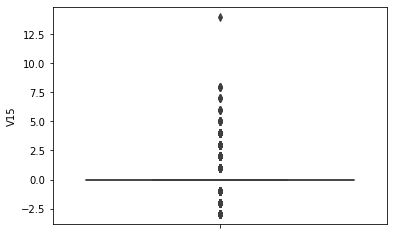

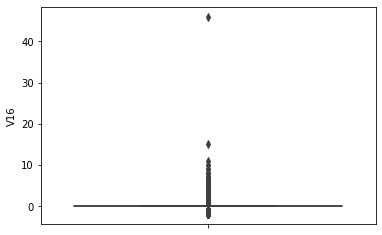

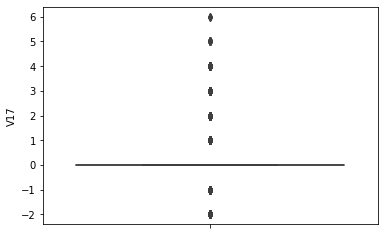

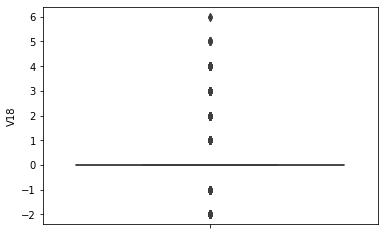

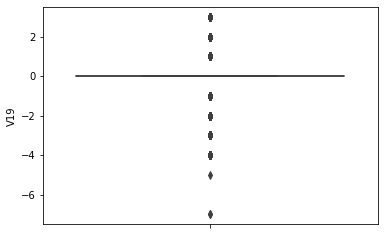

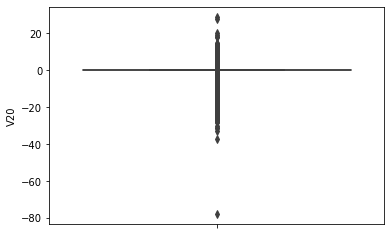

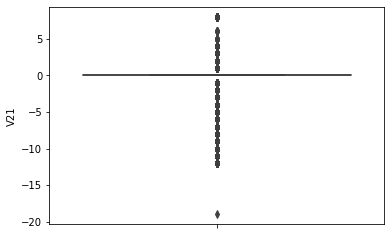

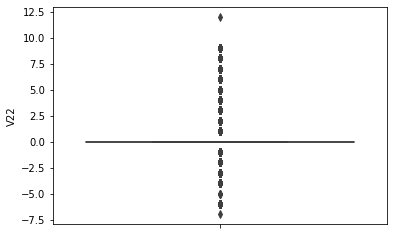

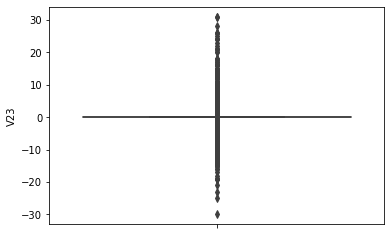

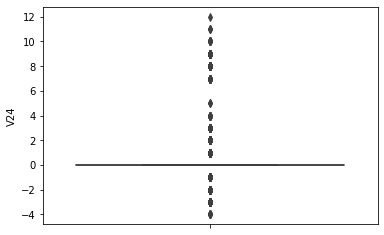

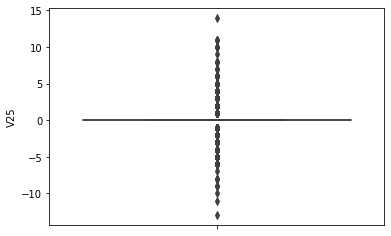

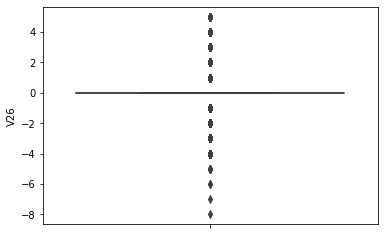

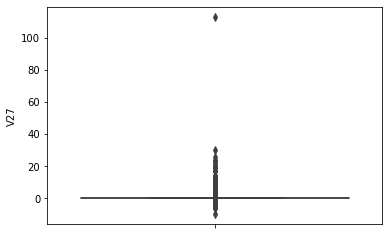

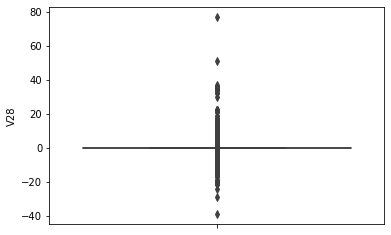

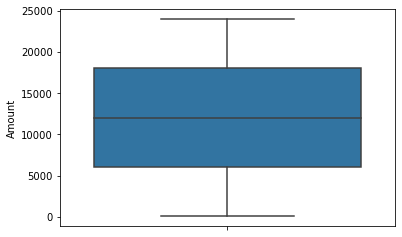

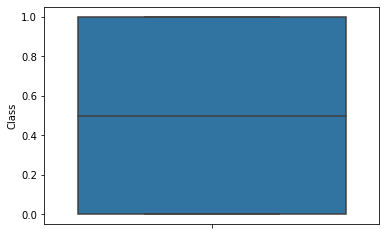

In [9]:
for col in dataset:
    sns.boxplot(data=dataset,y=dataset[col])
    plt.show()

In [10]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568630 entries, 0 to 568629
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   id      568630 non-null  int32
 1   V1      568630 non-null  int32
 2   V2      568630 non-null  int32
 3   V3      568630 non-null  int32
 4   V4      568630 non-null  int32
 5   V5      568630 non-null  int32
 6   V6      568630 non-null  int32
 7   V7      568630 non-null  int32
 8   V8      568630 non-null  int32
 9   V9      568630 non-null  int32
 10  V10     568630 non-null  int32
 11  V11     568630 non-null  int32
 12  V12     568630 non-null  int32
 13  V13     568630 non-null  int32
 14  V14     568630 non-null  int32
 15  V15     568630 non-null  int32
 16  V16     568630 non-null  int32
 17  V17     568630 non-null  int32
 18  V18     568630 non-null  int32
 19  V19     568630 non-null  int32
 20  V20     568630 non-null  int32
 21  V21     568630 non-null  int32
 22  V22     568630 non-n

In [11]:
dataset.drop('id',axis=1, inplace=True)

In [12]:
# select only the columns for correlation
selected_columns = list(set(dataset.columns) - set(['Class']))

# calculate correlations
corr_with_target1 = dataset[selected_columns + ['Class']].corr()['Class'][:-1]  # exclude last row because it's the correlation of target with itself


In [13]:
# create DataFrame from correlations
corr_df = pd.DataFrame({'Target': corr_with_target1})

# sort DataFrame by 'Target_2_4' in descending order
corr_df = corr_df.sort_values(by='Target', ascending=False)

# apply conditional formatting
corr_df.style.background_gradient(cmap='coolwarm').set_precision(2)


C:\Users\User\AppData\Local\Temp\ipykernel_13672\2161522437.py:8: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  corr_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Target
V4,0.54
V11,0.53
V2,0.27
V19,0.16
V26,0.07
V27,0.07
V20,0.07
V8,0.06
V25,0.05
V23,0.02


In [14]:
# Calculate the correlation matrix
corr_matrix = dataset.corr()

# Create a mask to ignore self-correlation
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Apply the mask to the correlation matrix
corr_matrix_masked = corr_matrix.mask(mask)

# Create a DataFrame of column pairs with correlation greater than 0.3
highly_correlated_pairs = [(col, row, corr_matrix_masked[col][row]) for col in corr_matrix_masked.columns for row in corr_matrix_masked.index if abs(corr_matrix_masked[col][row]) > 0.3]

# Convert the list of tuples to a DataFrame
highly_correlated_pairs_df = pd.DataFrame(highly_correlated_pairs, columns=['Column 1', 'Column 2', 'Correlation']).sort_values(by='Correlation', ascending=False)


In [15]:
highly_correlated_pairs_df

,Column 1,Column 2,Correlation
104,V17,V18,0.808790
100,V16,V17,0.753094
101,V16,V18,0.698056
70,V9,V10,0.665877
108,V20,V22,0.570634
...,...,...,...
56,V6,V8,-0.599456
17,V2,V7,-0.631881
16,V2,V5,-0.641929
107,V20,V21,-0.654797


In [16]:
highly_correlated_pairs_df['Column 1'].value_counts()

V1     14
V3     13
V4     12
V2     11
V9      8
V7      7
V10     7
V11     6
V5      6
V6      5
V12     5
V16     4
V14     4
V21     3
V17     2
V8      2
V20     2
V22     1
V18     1
Name: Column 1, dtype: int64

In [17]:
highly_correlated_pairs_df['Column 2'].value_counts()

V18      13
V17      12
V16      11
Class    10
V12       9
V11       8
V10       7
V14       6
V9        6
V7        5
V5        4
V6        3
V19       3
V4        3
V23       2
V3        2
V27       2
V22       2
V25       1
V28       1
V2        1
V8        1
V21       1
Name: Column 2, dtype: int64

In [18]:
df = dataset.copy()

In [19]:
df.drop(['V1','V4','V5','V6','V8','V2','V14','V12', 'V9','V10',
         'V11','V17','V16','V3','V18',
        'V21', 'V22'],axis=1,inplace=True)

In [20]:
# Calculate the correlation matrix
corr_matrix = df.corr()

# Create a mask to ignore self-correlation
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Apply the mask to the correlation matrix
corr_matrix_masked = corr_matrix.mask(mask)

# Create a DataFrame of column pairs with correlation greater than 0.3
highly_correlated_pairs = [(col, row, corr_matrix_masked[col][row]) for col in corr_matrix_masked.columns for row in corr_matrix_masked.index if abs(corr_matrix_masked[col][row]) > 0.3]

# Convert the list of tuples to a DataFrame
highly_correlated_pairs_df = pd.DataFrame(highly_correlated_pairs, columns=['Column 1', 'Column 2', 'Correlation']).sort_values(by='Correlation', ascending=False)


In [21]:
highly_correlated_pairs_df

,Column 1,Column 2,Correlation


In [22]:
highly_correlated_pairs_df['Column 1'].value_counts()

Series([], Name: Column 1, dtype: int64)

In [23]:
highly_correlated_pairs_df['Column 2'].value_counts()

Series([], Name: Column 2, dtype: int64)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568630 entries, 0 to 568629
Data columns (total 13 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   V7      568630 non-null  int32
 1   V13     568630 non-null  int32
 2   V15     568630 non-null  int32
 3   V19     568630 non-null  int32
 4   V20     568630 non-null  int32
 5   V23     568630 non-null  int32
 6   V24     568630 non-null  int32
 7   V25     568630 non-null  int32
 8   V26     568630 non-null  int32
 9   V27     568630 non-null  int32
 10  V28     568630 non-null  int32
 11  Amount  568630 non-null  int32
 12  Class   568630 non-null  int32
dtypes: int32(13)
memory usage: 28.2 MB


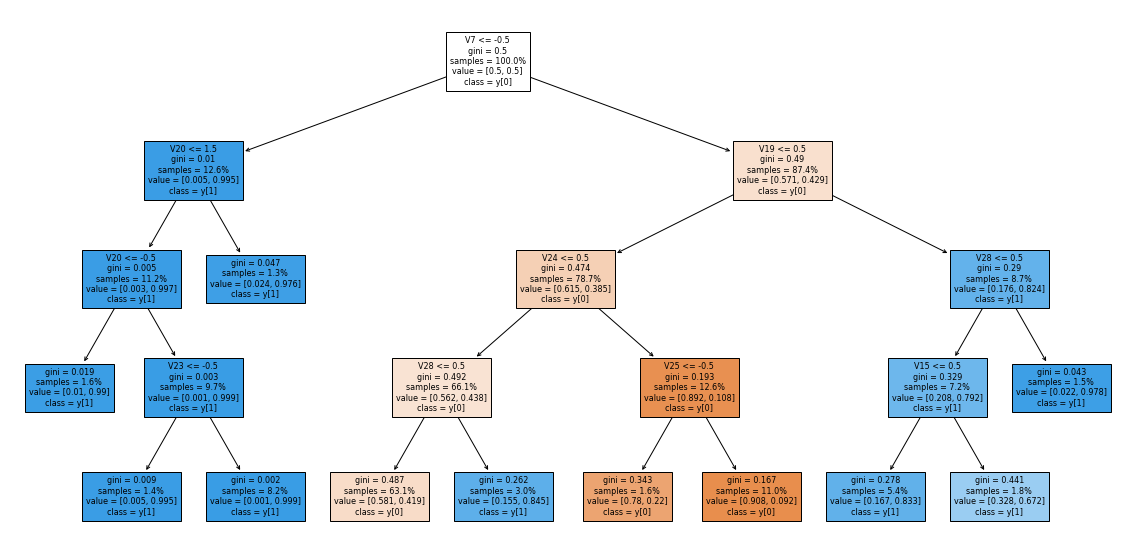

In [25]:
df['Class'].value_counts(normalize=True) * 100 #(Normalize target)
X = df.drop('Class', axis=1)  # predictors
y = df['Class']  # target

# Initialize and fit the decision tree
clf = tree.DecisionTreeClassifier(max_depth=4, min_samples_leaf=5000, random_state=42)
clf = clf.fit(X, y)

# Visualize the decision tree
fig, ax = plt.subplots(figsize=(20, 10))  # adjust size as needed

tree.plot_tree(clf, ax=ax, feature_names=X.columns, class_names=True, proportion=True, filled=True, fontsize=8)

plt.show()


## Modelling


In [26]:
# Save random 10% for testing
data_length = len(df)
separation_ratio = 0.1
separation_count = int(data_length * separation_ratio)
# Shuffle the rows of the DataFrame
df_shuffled = df.sample(frac=1, random_state=1)  # 'frac=1' shuffles all rows

# Select a random subset for testing
random_subset = df_shuffled.head(separation_count)

random_subset.to_csv('test_credit.csv',index=False)

In [27]:
data = training_data = df_shuffled.iloc[separation_count:]

In [28]:
random_subset[random_subset['Class']==1].count()/len(random_subset)

V7        0.500607
V13       0.500607
V15       0.500607
V19       0.500607
V20       0.500607
V23       0.500607
V24       0.500607
V25       0.500607
V26       0.500607
V27       0.500607
V28       0.500607
Amount    0.500607
Class     0.500607
dtype: float64

In [29]:
data[data['Class']==1].count()/len(data)

V7        0.499933
V13       0.499933
V15       0.499933
V19       0.499933
V20       0.499933
V23       0.499933
V24       0.499933
V25       0.499933
V26       0.499933
V27       0.499933
V28       0.499933
Amount    0.499933
Class     0.499933
dtype: float64

In [30]:
X = data.drop('Class',axis=1)
Y = data['Class']

X_train,X_val,y_train,y_val = train_test_split(X,Y,test_size=0.2,random_state=0)

In [31]:
#  Feature Scaling-----------------------------------------------------------------------


sc_X = StandardScaler()
#sc_X=MinMaxScaler()

X_train = pd.DataFrame(sc_X.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

X_val = pd.DataFrame(sc_X.transform(X_val), columns=X_val.columns, index=X_val.index)


In [32]:

models = []

models.append(('Logistic Regression', LogisticRegression(solver='liblinear', random_state = 0,
                                                         class_weight='balanced',  n_jobs=6)))

models.append(('SVC', SVC(C=0.3, tol=0.05,  max_iter=100, kernel = 'linear', verbose=True, random_state = 0)))


models.append(('Kernel SVM', SVC(C=0.3, tol=0.05,  max_iter=100, kernel = 'rbf', verbose=True, random_state = 0)))


models.append(('KNN', KNeighborsClassifier(n_neighbors = 100, metric = 'minkowski', p = 2,  n_jobs=6)))


models.append(('Gaussian NB', GaussianNB()))


models.append(('Decision Tree Classifier',
               DecisionTreeClassifier(max_depth=6, criterion = 'entropy', random_state = 0)))


models.append(('Random Forest', RandomForestClassifier(max_depth=5, min_samples_leaf=500,
    n_estimators=100, criterion = 'entropy', random_state = 0, n_jobs=6)))


models.append(('Gradient Boosting', GradientBoostingClassifier(max_depth=5, min_samples_leaf=500,
    n_estimators=150, criterion = 'friedman_mse', random_state = 0)))


------
Logistic Regression


C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 

Train-> [0.71542665 0.71467214 0.71354785 0.71788877 0.71215597]


C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 

Validation -> [0.71766665 0.71416623 0.71209928 0.71117636 0.71550717]
------
SVC
[LibSVM]

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


... (75 outputs left out)

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


[LibSVM]

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Validation -> [0.40301811 0.46409581 0.37901833 0.40920669 0.4174749 ]
------
KNN
Train-> [0.90324693 0.90180086 0.90206005 0.90349279 0.90074463]
Validation -> [0.88230722 0.87561714 0.87909734 0.88017873 0.88014097]
------
Gaussian NB
Train-> [0.81841711 0.81739807 0.81827347 0.8198602  0.81307996]
Validation -> [0.81717839 0.8113908  0.81217237 0.81378569 0.80942106]
------
Decision Tree Classifier
Train-> [0.81442995 0.81389099 0.81409978 0.81619745 0.8112552 ]
Validation -> [0.81111604 0.80522629 0.81231471 0.80958605 0.81090036]
------
Random Forest
Train-> [0.84058773 0.8417732  0.84290625 0.84483418 0.84223763]
Validation -> [0.84197909 0.83077758 0.83681495 0.83696616 0.83575092]
------
Gradient Boosting
Train-> [0.89658607 0.89677227 0.89619239 0.89659034 0.89403899]
Validation -> [0.88442702 0.87795508 0.88289879 0.8822549  0.88175327]


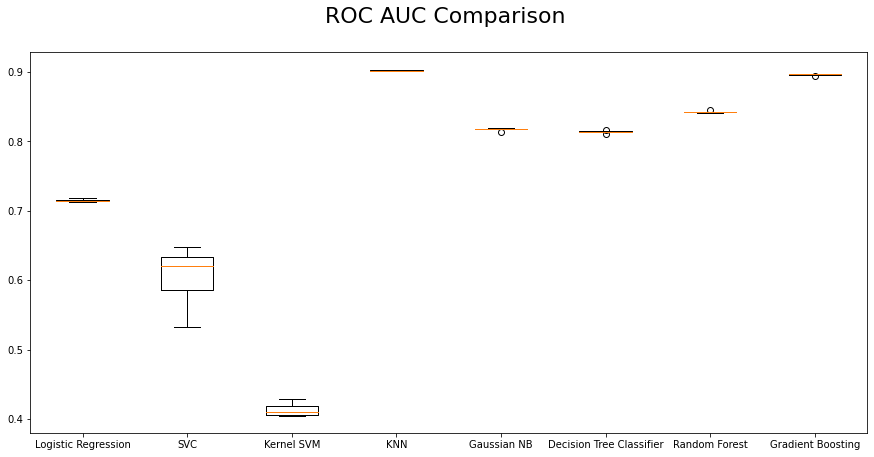

In [33]:
#Evaluating Model Results: 

    
acc_results = []
auc_results = []
names = []
# set table to table to populate with performance results
col = ['Algorithm', 'ROC AUC Mean', 'ROC AUC STD', 
       'Accuracy Mean', 'Accuracy STD']

model_results = pd.DataFrame(columns=col)
i = 0
# evaluate each model using k-fold cross-validation
for name, model in models:
    print('------')
    print(name)
    kfold = model_selection.KFold(shuffle=True,
        n_splits=5, random_state=0)  # 5-fold cross-validation

    cv_acc_results = model_selection.cross_val_score(  # accuracy scoring
        model, X_train, y_train, cv=kfold, scoring='accuracy')

    cv_auc_results = model_selection.cross_val_score(  # roc_auc scoring
        model, X_train, y_train, cv=kfold, scoring='roc_auc')
    
    
    print('Train->', model_selection.cross_val_score( model, X_train, y_train, cv=kfold, scoring='roc_auc'))
    print('Validation ->', model_selection.cross_val_score( model, X_val, y_val, cv=kfold, scoring='roc_auc'))

    acc_results.append(cv_acc_results)
    auc_results.append(cv_auc_results)
    names.append(name)
    model_results.loc[i] = [name,
                         round(cv_auc_results.mean()*100, 2),
                         round(cv_auc_results.std()*100, 2),
                         round(cv_acc_results.mean()*100, 2),
                         round(cv_acc_results.std()*100, 2)
                         ]
    i += 1
    
model_results.sort_values(by=['ROC AUC Mean'], ascending=False)
fig = plt.figure(figsize=(15, 7))
ax = fig.add_subplot(111)
plt.boxplot(auc_results)
ax.set_xticklabels(names)


#plt.ylabel('ROC AUC Score\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
#plt.xlabel('\n Baseline Classification Algorithms\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('ROC AUC Comparison \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()


In [34]:
#normalising
norm=MinMaxScaler()

X_train_norm = pd.DataFrame(norm.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

X_val_norm = pd.DataFrame(norm.transform(X_val), columns=X_val.columns, index=X_val.index)



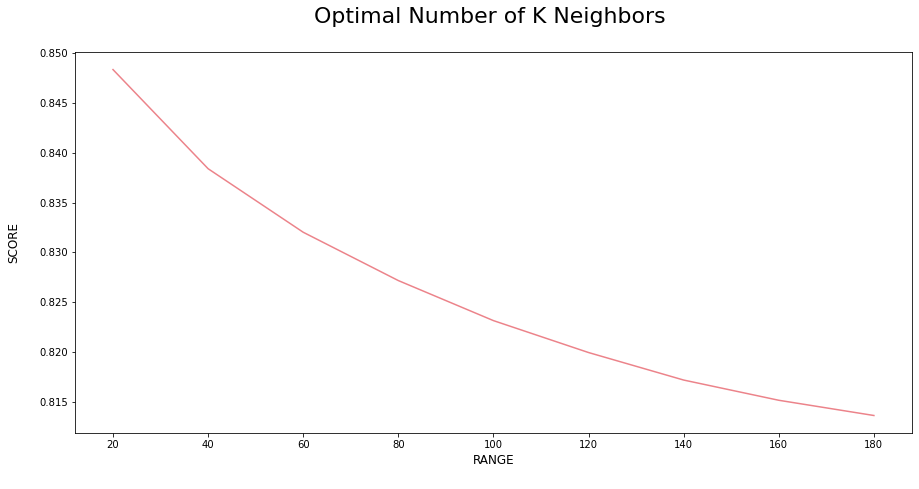

In [35]:
#Identify optimal number of K neighbors for KNN Model:


score_array = []
for each in range(20,200,20):
    knn_loop = KNeighborsClassifier(n_neighbors = each, metric = 'minkowski', p = 2,  n_jobs=6) 
    knn_loop.fit(X_train_norm,y_train)
    score_array.append(cross_val_score( knn_loop, X_train_norm, y_train, cv=2, scoring='roc_auc').mean())

fig = plt.figure(figsize=(15, 7))
plt.plot(range(20,200,20),score_array, color = '#ec838a')


plt.ylabel('SCORE\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('RANGE\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('Optimal Number of K Neighbors \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()


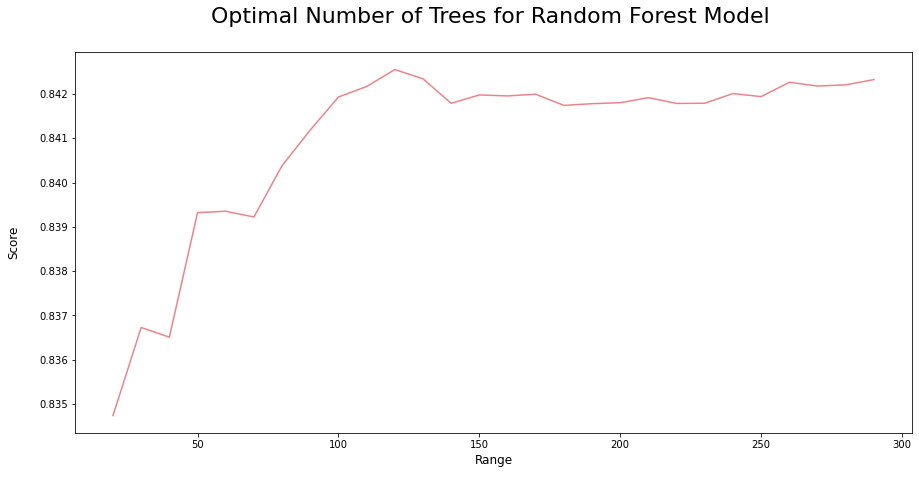

In [36]:
#Identify optimal number of trees for Random Forest Model:
 
score_array = []
for each in range(20,300,10):
    rf_loop = RandomForestClassifier(max_depth=5, min_samples_leaf=500, n_estimators = each, criterion = 'entropy', random_state = 1, n_jobs=6) 
    rf_loop.fit(X_train,y_train)
    #score_array.append(rf_loop.score(X_test,y_test))
    score_array.append(cross_val_score( rf_loop, X_train, y_train, cv=2, scoring='roc_auc').mean())

 
fig = plt.figure(figsize=(15, 7))
plt.plot(range(20,300,10),score_array, color = '#ec838a')


plt.ylabel('Score\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('Range\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('Optimal Number of Trees for Random Forest Model \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()


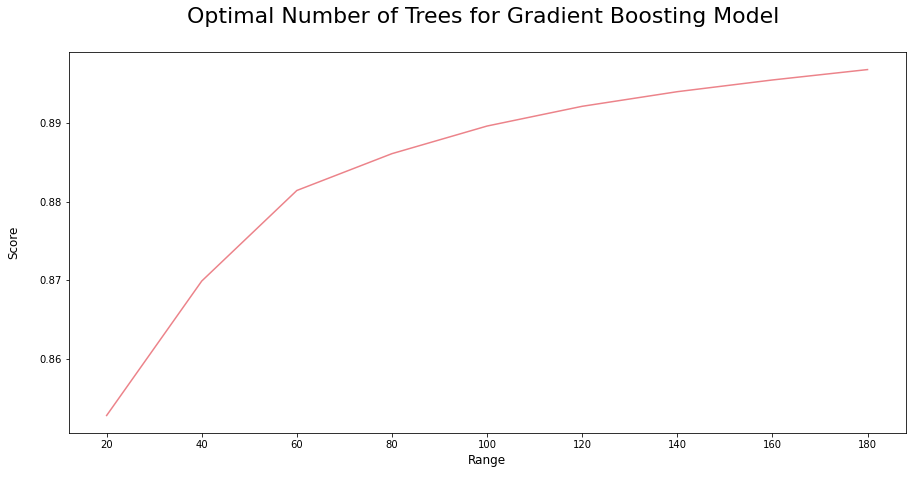

In [37]:
#Identify optimal number of trees for Gradient Boosting Model:

 
score_array = []
for each in range(20,200,20):
    gr_loop = GradientBoostingClassifier(n_estimators = each, criterion = 'friedman_mse', random_state = 1, max_depth=5, min_samples_leaf=500) 
    gr_loop.fit(X_train,y_train)
    #score_array.append(gr_loop.score(X_test,y_test))
    score_array.append(cross_val_score( gr_loop, X_train, y_train, cv=2, scoring='roc_auc').mean())

 
fig = plt.figure(figsize=(15, 7))
plt.plot(range(20,200,20),score_array, color = '#ec838a')


plt.ylabel('Score\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('Range\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('Optimal Number of Trees for Gradient Boosting Model \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()


In [39]:
#--Gradient Boosting Classifier-----------------

# Fitting Gradient Boosting Classifierb to the Training set 
classifier_GR = GradientBoostingClassifier(n_estimators = 120, criterion = 'friedman_mse', random_state = 1, max_depth=5, min_samples_leaf=500)
classifier_GR.fit(X_train, y_train)

# Predicting the Test set results
y_pred_GR_tr = classifier_GR.predict(X_train)
y_pred_GR_tr_Pr = classifier_GR.predict_proba(X_train)[:, 1]

#Evaluate results

# Train part
roc_auc=roc_auc_score(y_train, y_pred_GR_tr_Pr )
acc = accuracy_score(y_train, y_pred_GR_tr )
prec = precision_score(y_train, y_pred_GR_tr )
rec = recall_score(y_train, y_pred_GR_tr )
f1 = f1_score(y_train, y_pred_GR_tr )
f2 = fbeta_score(y_train, y_pred_GR_tr, beta=2.0)

results = pd.DataFrame([['GBM', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = results.append(model_results, ignore_index = True)

# Validation part
y_pred_GR_val = classifier_GR.predict(X_val)
y_pred_GR_val_Pr = classifier_GR.predict_proba(X_val)[:, 1]


roc_auc=roc_auc_score(y_val, y_pred_GR_val_Pr )
acc = accuracy_score(y_val, y_pred_GR_val )
prec = precision_score(y_val, y_pred_GR_val )
rec = recall_score(y_val, y_pred_GR_val )
f1 = f1_score(y_val, y_pred_GR_val )
f2 = fbeta_score(y_val, y_pred_GR_val, beta=2.0)

model_results = pd.DataFrame([['GBM', 'Validation', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = results.append(model_results, ignore_index = True)


C:\Users\User\AppData\Local\Temp\ipykernel_13672\3828859142.py:24: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)
C:\Users\User\AppData\Local\Temp\ipykernel_13672\3828859142.py:41: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


In [40]:
#--KNeighbors-----------------

# Fitting Kneighbors to the Training set 
classifier_KNN = KNeighborsClassifier(n_neighbors = 100, metric = 'minkowski', p = 2,  n_jobs=6) 
classifier_KNN.fit(X_train, y_train)

# Predicting the Test set results
y_pred_KNN_tr = classifier_KNN.predict(X_train)
y_pred_KNN_tr_Pr = classifier_KNN.predict_proba(X_train)[:, 1]


#Evaluate results

# Train part
roc_auc=roc_auc_score(y_train, y_pred_KNN_tr_Pr )
acc = accuracy_score(y_train, y_pred_KNN_tr )
prec = precision_score(y_train, y_pred_KNN_tr )
rec = recall_score(y_train, y_pred_KNN_tr )
f1 = f1_score(y_train, y_pred_KNN_tr )
f2 = fbeta_score(y_train, y_pred_KNN_tr, beta=2.0)

model_results = pd.DataFrame([['K-NN', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = results.append(model_results, ignore_index = True)

# Validation part
y_pred_KNN_val = classifier_KNN.predict(X_val)
y_pred_KNN_val_Pr = classifier_KNN.predict_proba(X_val)[:, 1]


roc_auc=roc_auc_score(y_val, y_pred_KNN_val_Pr )
acc = accuracy_score(y_val, y_pred_KNN_val )
prec = precision_score(y_val, y_pred_KNN_val )
rec = recall_score(y_val, y_pred_KNN_val )
f1 = f1_score(y_val, y_pred_KNN_val )
f2 = fbeta_score(y_val, y_pred_KNN_val, beta=2.0)

model_results = pd.DataFrame([['K-NN', 'Validation', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = results.append(model_results, ignore_index = True)


C:\Users\User\AppData\Local\Temp\ipykernel_13672\3892502642.py:25: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)
C:\Users\User\AppData\Local\Temp\ipykernel_13672\3892502642.py:42: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


In [41]:
#--Random Forest Classifier-----------------

# Fitting Random Forest Classifier to the Training set 
classifier_RF = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 1, max_depth=5, min_samples_leaf=500,n_jobs=6)
classifier_RF.fit(X_train, y_train)

# Predicting the Test set results
y_pred_RF_tr = classifier_RF.predict(X_train)
y_pred_RF_tr_Pr = classifier_RF.predict_proba(X_train)[:, 1]

#Evaluate results

# Train part
roc_auc=roc_auc_score(y_train, y_pred_RF_tr_Pr )
acc = accuracy_score(y_train, y_pred_RF_tr )
prec = precision_score(y_train, y_pred_RF_tr )
rec = recall_score(y_train, y_pred_RF_tr )
f1 = f1_score(y_train, y_pred_RF_tr )
f2 = fbeta_score(y_train, y_pred_RF_tr, beta=2.0)

model_results = pd.DataFrame([['RFC', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = results.append(model_results, ignore_index = True)

# Validation part
y_pred_RF_val = classifier_RF.predict(X_val)
y_pred_RF_val_Pr = classifier_RF.predict_proba(X_val)[:, 1]


roc_auc=roc_auc_score(y_val, y_pred_RF_val_Pr )
acc = accuracy_score(y_val, y_pred_RF_val )
prec = precision_score(y_val, y_pred_RF_val )
rec = recall_score(y_val, y_pred_RF_val )
f1 = f1_score(y_val, y_pred_RF_val )
f2 = fbeta_score(y_val, y_pred_RF_val, beta=2.0)

model_results = pd.DataFrame([['RFC', 'Validation', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = results.append(model_results, ignore_index = True)


C:\Users\User\AppData\Local\Temp\ipykernel_13672\830307266.py:24: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)
C:\Users\User\AppData\Local\Temp\ipykernel_13672\830307266.py:41: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


In [42]:
results

,Model,Dataset,AUC,Accuracy,Precision,Recall,F1 Score,F2 Score
0,GBM,Train,0.893930,0.802972,0.892252,0.688841,0.777462,0.721749
1,GBM,Train,0.893930,0.802972,0.892252,0.688841,0.777462,0.721749
2,GBM,Validation,0.890741,0.799861,0.890880,0.684448,0.774138,0.717709
3,K-NN,Train,0.909112,0.817285,0.867878,0.748208,0.803612,0.769427
4,K-NN,Validation,0.901697,0.810042,0.861252,0.740169,0.796133,0.761583
5,RFC,Train,0.841695,0.724677,0.906427,0.500636,0.645017,0.549869
6,RFC,Validation,0.839725,0.724622,0.908981,0.500595,0.645629,0.550017


In [44]:
def calculate_lift(y_true, y_pred_prob, num_bins):
    # Sorting instances by prediction probability
    sorted_indices = np.argsort(y_pred_prob)[::-1]
    y_true = y_true[sorted_indices]

    # Number of instances in the entire dataset
    n_total = len(y_true)
    # Number of positive instances in the entire dataset
    n_positives_total = np.sum(y_true)
    # Size of each bin
    bin_size = n_total // num_bins

    if n_positives_total == 0:
        return [np.nan] * num_bins, [(i*100/num_bins, (i+1)*100/num_bins) for i in range(num_bins)]

    lift_values = []
    percentages = []
    for i in range(num_bins):
        start_idx = i * bin_size
        end_idx = (i + 1) * bin_size if i != (num_bins - 1) else n_total
        bin_labels = y_true[start_idx:end_idx]

        # Number of positive instances in the bin
        n_positives_bin = np.sum(bin_labels)

        # Calculating the lift for the bin
        expected_positives_bin = n_positives_total * bin_size / n_total
        lift = n_positives_bin / expected_positives_bin if expected_positives_bin > 0 else np.nan
        lift_values.append(lift)

        # Adding the percentage range for this bin
        percentages.append((i*100/num_bins, (i+1)*100/num_bins))

    return lift_values, percentages

# List of bin numbers
bin_numbers = [5, 10, 20]

# Iterate through the bin numbers
for num_bins in bin_numbers:
    lift_values_KNN, percentages = calculate_lift(np.array(y_val), y_pred_KNN_val_Pr, num_bins)
    lift_values_GRB, percentages = calculate_lift(np.array(y_val), y_pred_GR_val_Pr, num_bins)
    lift_values_RFC, percentages = calculate_lift(np.array(y_val), y_pred_RF_val_Pr, num_bins)

    
    


    lift_df = pd.DataFrame({
        'Lift_KNN': lift_values_KNN,
        'Lift_GRB': lift_values_GRB,                      
        'Percentage': [f'{p[0]} - {p[1]}%' for p in percentages]
    })

    # Apply styling
    styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)

    # Display the result
    print(f"Results for {num_bins} bins:")
    display(styled_lift)


Results for 5 bins:


C:\Users\User\AppData\Local\Temp\ipykernel_13672\1092921877.py:56: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Lift_KNN,Lift_GRB,Percentage
0,1.99,1.98,0.0 - 20.0%
1,1.57,1.52,20.0 - 40.0%
2,0.82,0.83,40.0 - 60.0%
3,0.55,0.57,60.0 - 80.0%
4,0.08,0.11,80.0 - 100.0%


Results for 10 bins:


,Lift_KNN,Lift_GRB,Percentage
0,1.99,1.99,0.0 - 10.0%
1,1.99,1.96,10.0 - 20.0%
2,1.80,1.75,20.0 - 30.0%
3,1.33,1.30,30.0 - 40.0%
4,0.89,0.89,40.0 - 50.0%
5,0.75,0.77,50.0 - 60.0%
6,0.67,0.67,60.0 - 70.0%
7,0.43,0.46,70.0 - 80.0%
8,0.15,0.19,80.0 - 90.0%
9,0.00,0.02,90.0 - 100.0%


Results for 20 bins:


,Lift_KNN,Lift_GRB,Percentage
0,1.99,2.00,0.0 - 5.0%
1,1.99,1.99,5.0 - 10.0%
2,1.99,1.99,10.0 - 15.0%
3,1.98,1.93,15.0 - 20.0%
4,1.88,1.84,20.0 - 25.0%
5,1.72,1.66,25.0 - 30.0%
6,1.47,1.41,30.0 - 35.0%
7,1.19,1.18,35.0 - 40.0%
8,0.94,0.99,40.0 - 45.0%
9,0.83,0.79,45.0 - 50.0%


In [47]:
# Gradient Boosting
feature_names = classifier_GR.feature_names_in_
feature_importances_GR = classifier_GR.feature_importances_
important_features_GR = sorted(zip(feature_names, feature_importances_GR), key=lambda x: x[1], reverse=True)

# Random Forest
feature_importances_RF = classifier_RF.feature_importances_
important_features_RF = sorted(zip(feature_names, feature_importances_RF), key=lambda x: x[1], reverse=True)


In [48]:
# Creating DataFrame
final_df = pd.DataFrame({
    'RF_features': [f for f, _ in important_features_RF],
    'RF_features_Importance': [imp for _, imp in important_features_RF],
    'GRB_features': [f for f, _ in important_features_GR],
    'GRB_features_importance': [imp for _, imp in important_features_GR]
})

final_df.style.background_gradient(cmap='coolwarm').set_precision(2)


C:\Users\User\AppData\Local\Temp\ipykernel_13672\2495534135.py:9: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  final_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,RF_features,RF_features_Importance,GRB_features,GRB_features_importance
0,V7,0.32,V7,0.32
1,V27,0.19,V19,0.19
2,V19,0.19,V24,0.15
3,V24,0.11,V28,0.07
4,V28,0.10,V27,0.07
5,V20,0.04,V15,0.05
6,V23,0.02,V13,0.04
7,V26,0.01,V26,0.03
8,V25,0.01,V25,0.03
9,V13,0.01,V23,0.03


In [49]:
# Creating DataFrame
importances_df = pd.DataFrame({
    'Feature': feature_names,
    'RFC_importance': feature_importances_RF,
    'GRB_Importance': feature_importances_GR
}).sort_values(by='GRB_Importance', ascending=False)

importances_df.style.background_gradient(cmap='coolwarm').set_precision(2)



C:\Users\User\AppData\Local\Temp\ipykernel_13672\50025291.py:8: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  importances_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Feature,RFC_importance,GRB_Importance
0,V7,0.32,0.32
3,V19,0.19,0.19
6,V24,0.11,0.15
10,V28,0.10,0.07
9,V27,0.19,0.07
2,V15,0.00,0.05
1,V13,0.01,0.04
8,V26,0.01,0.03
7,V25,0.01,0.03
5,V23,0.02,0.03


In [51]:
selected_features = importances_df[
    (importances_df['RFC_importance'] > 0.1) |
    (importances_df['GRB_Importance'] > 0.1)
]

selected_features.style.background_gradient(cmap='coolwarm').set_precision(2)


C:\Users\User\AppData\Local\Temp\ipykernel_13672\4093344537.py:6: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  selected_features.style.background_gradient(cmap='coolwarm').set_precision(2)


,Feature,RFC_importance,GRB_Importance
0,V7,0.32,0.32
3,V19,0.19,0.19
6,V24,0.11,0.15
9,V27,0.19,0.07


In [52]:
#shortlist of important features
shortlist=selected_features.Feature.tolist()


In [53]:
# Fitting selected models on data with selected features

GRB = GradientBoostingClassifier(n_estimators = 120, criterion = 'friedman_mse', random_state = 1, max_depth=5, min_samples_leaf=500)
GRB.fit(X_train[shortlist], y_train)


GradientBoostingClassifier(max_depth=5, min_samples_leaf=500, n_estimators=120,
                           random_state=1)

In [54]:
RF = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 1, max_depth=5, min_samples_leaf=500,n_jobs=6)
RF.fit(X_train[shortlist], y_train)

RandomForestClassifier(criterion='entropy', max_depth=5, min_samples_leaf=500,
                       n_jobs=6, random_state=1)

In [55]:
# Gradient Boosting
importances_GR = GRB.feature_importances_
# Random Forest
importances_RF = RF.feature_importances_

In [56]:
# Creating DataFrame
importances_df = pd.DataFrame({
    'Feature': shortlist,
    'RFC_Importance': importances_RF,
    'GRB_Importance': importances_GR
}).sort_values(by='GRB_Importance', ascending=False)

importances_df.style.background_gradient(cmap='coolwarm').set_precision(2)

C:\Users\User\AppData\Local\Temp\ipykernel_13672\127462449.py:8: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  importances_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Feature,RFC_Importance,GRB_Importance
0,V7,0.37,0.43
1,V19,0.23,0.25
2,V24,0.18,0.20
3,V27,0.22,0.11


In [57]:
def scores (model, name):
    
    # Predicting the Test set results
    y_pred_tr = model.predict(X_train[shortlist])
    y_pred_tr_Pr = model.predict_proba(X_train[shortlist])[:, 1]

    #Evaluate results

    # Train part
    roc_auc=roc_auc_score(y_train, y_pred_tr_Pr )
    prec = precision_score(y_train, y_pred_tr )
    rec = recall_score(y_train, y_pred_tr )

    results = pd.DataFrame([[name, 'Train', roc_auc,  prec, rec]],
                   columns = ['Model', 'Dataset', 'AUC',  'Precision', 'Recall'])


    # Validation part
    y_pred_val = model.predict(X_val[shortlist])
    y_pred_val_Pr = model.predict_proba(X_val[shortlist])[:, 1]


    roc_auc=roc_auc_score(y_val, y_pred_val_Pr )
    prec = precision_score(y_val, y_pred_val )
    rec = recall_score(y_val, y_pred_val )

    model_results = pd.DataFrame([[name, 'Validation', roc_auc,  prec, rec]],
                   columns = ['Model', 'Dataset', 'AUC',  'Precision', 'Recall'])

    results = results.append(model_results, ignore_index = True)
    return(results)


In [58]:
GRB_scores=scores (GRB, 'GRB')
RF_scores = scores(RF,'RF')

pd.concat([RF_scores, GRB_scores], axis=0).reset_index(drop=True)

C:\Users\User\AppData\Local\Temp\ipykernel_13672\2046832522.py:30: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)
C:\Users\User\AppData\Local\Temp\ipykernel_13672\2046832522.py:30: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


,Model,Dataset,AUC,Precision,Recall
0,RF,Train,0.804754,0.822421,0.613127
1,RF,Validation,0.802885,0.824020,0.610653
2,GRB,Train,0.817809,0.857575,0.596775
3,GRB,Validation,0.815818,0.857847,0.593457


In [59]:
# List of bin numbers
bin_numbers = [5, 10, 20]

# Iterate through the bin numbers
for num_bins in bin_numbers:
    lift_values_GRB, percentages = calculate_lift(np.array(y_val), GRB.predict_proba(X_val[shortlist])[:, 1], num_bins)
    lift_values_RF, percentages = calculate_lift(np.array(y_val), RF.predict_proba(X_val[shortlist])[:, 1], num_bins)

    lift_df = pd.DataFrame({
        'Lift_GRB': lift_values_GRB,        
        'Lift_RF': lift_values_RF,        
        'Percentage': [f'{p[0]} - {p[1]}%' for p in percentages]
    })

    # Apply styling
    styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)

    # Display the result
    print(f"Results for {num_bins} bins:")
    display(styled_lift)


Results for 5 bins:


C:\Users\User\AppData\Local\Temp\ipykernel_13672\1029979686.py:16: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Lift_GRB,Lift_RF,Percentage
0,1.93,1.92,0.0 - 20.0%
1,1.26,1.22,20.0 - 40.0%
2,0.76,0.76,40.0 - 60.0%
3,0.74,0.75,60.0 - 80.0%
4,0.31,0.35,80.0 - 100.0%


Results for 10 bins:


C:\Users\User\AppData\Local\Temp\ipykernel_13672\1029979686.py:16: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Lift_GRB,Lift_RF,Percentage
0,1.99,1.99,0.0 - 10.0%
1,1.87,1.85,10.0 - 20.0%
2,1.49,1.45,20.0 - 30.0%
3,1.04,0.98,30.0 - 40.0%
4,0.76,0.75,40.0 - 50.0%
5,0.75,0.76,50.0 - 60.0%
6,0.74,0.74,60.0 - 70.0%
7,0.74,0.76,70.0 - 80.0%
8,0.48,0.55,80.0 - 90.0%
9,0.14,0.16,90.0 - 100.0%


Results for 20 bins:


C:\Users\User\AppData\Local\Temp\ipykernel_13672\1029979686.py:16: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Lift_GRB,Lift_RF,Percentage
0,1.99,2.00,0.0 - 5.0%
1,1.99,1.99,5.0 - 10.0%
2,1.96,1.93,10.0 - 15.0%
3,1.78,1.77,15.0 - 20.0%
4,1.64,1.54,20.0 - 25.0%
5,1.33,1.36,25.0 - 30.0%
6,1.23,1.27,30.0 - 35.0%
7,0.84,0.69,35.0 - 40.0%
8,0.78,0.76,40.0 - 45.0%
9,0.75,0.73,45.0 - 50.0%


1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36


,Classifier,Train AUC-ROC,Validation AUC-ROC,AUC_ROC_STD_on_Validation,Train Precision,Validation Precision,Train Recall,Validation Recall,learning_rate,max_depth,min_samples_split,n_estimators
0,GradientBoostingClassifier,0.812872,0.812569,0.002557,0.829714,0.829626,0.613756,0.613777,0.05,4,1000,100
1,GradientBoostingClassifier,0.812974,0.812867,0.001874,0.833270,0.833237,0.612495,0.612480,0.05,4,1000,120
2,GradientBoostingClassifier,0.814378,0.814045,0.002713,0.833145,0.833123,0.614584,0.614519,0.05,4,1000,140
3,GradientBoostingClassifier,0.813109,0.812777,0.001853,0.829837,0.829757,0.613959,0.613950,0.05,4,300,100
4,GradientBoostingClassifier,0.813472,0.813196,0.001712,0.834264,0.834203,0.612389,0.612394,0.05,4,300,120
5,GradientBoostingClassifier,0.815347,0.814817,0.002561,0.833096,0.832965,0.615321,0.615246,0.05,4,300,140
6,GradientBoostingClassifier,0.817935,0.817902,0.001062,0.852782,0.852484,0.601215,0.601117,0.05,5,1000,100
7,GradientBoostingClassifier,0.818304,0.818276,0.001004,0.852257,0.852134,0.604250,0.604241,0.05,5,1000,120
8,GradientBoostingClassifier,0.818681,0.818633,0.000882,0.854172,0.854092,0.602925,0.602943,0.05,5,1000,140
9,GradientBoostingClassifier,0.817600,0.817224,0.001947,0.852563,0.852161,0.601108,0.601011,0.05,5,300,100


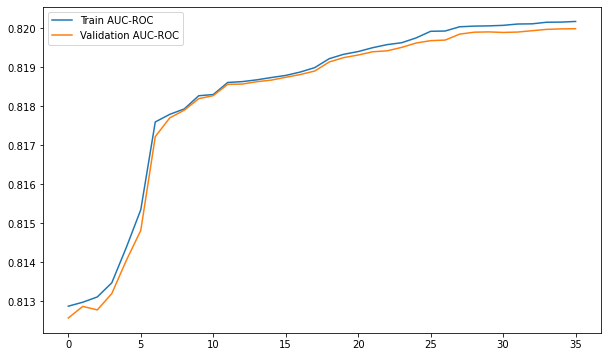

In [62]:
from sklearn.model_selection import  KFold, ParameterGrid


# Define the GradientBoostingClassifier
clf = GradientBoostingClassifier()

# Define the hyperparameters and their possible values
param_grid = {
    'n_estimators': [100, 120, 140],
   'learning_rate': [ 0.05, 0.1, 0.5],
   'max_depth': [4, 5],
   'min_samples_split': [1000, 300],
#   'min_samples_leaf': [200, 400],
}




kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for params in ParameterGrid(param_grid):
    train_aucs, val_aucs, train_precisions, val_precisions, train_recalls, val_recalls = [], [], [], [], [], []
    for train_index, val_index in kf.split(X[shortlist], Y):
        X_train_fold, X_val_fold = X[shortlist].iloc[train_index], X[shortlist].iloc[val_index]
        y_train_fold, y_val_fold = Y.iloc[train_index], Y.iloc[val_index]

        clf.set_params(**params)
        clf.fit(X_train_fold, y_train_fold)

        y_train_pred = clf.predict_proba(X_train_fold)[:, 1]
        y_val_pred = clf.predict_proba(X_val_fold)[:, 1]

        train_auc = roc_auc_score(y_train_fold, y_train_pred)
        val_auc = roc_auc_score(y_val_fold, y_val_pred)

        train_precision = precision_score(y_train_fold, (y_train_pred > 0.5).astype(int))
        val_precision = precision_score(y_val_fold, (y_val_pred > 0.5).astype(int))

        train_recall = recall_score(y_train_fold, (y_train_pred > 0.5).astype(int))
        val_recall = recall_score(y_val_fold, (y_val_pred > 0.5).astype(int))

        train_aucs.append(train_auc)
        val_aucs.append(val_auc)
        train_precisions.append(train_precision)
        val_precisions.append(val_precision)
        train_recalls.append(train_recall)
        val_recalls.append(val_recall)
        
    results_dict = {
        "Classifier": 'GradientBoostingClassifier',
        "Train AUC-ROC": np.mean(train_aucs),
        "Validation AUC-ROC": np.mean(val_aucs),
        "AUC_ROC_STD_on_Validation": np.std(val_aucs),
        "Train Precision": np.mean(train_precisions),
        "Validation Precision": np.mean(val_precisions),
        "Train Recall": np.mean(train_recalls),
        "Validation Recall": np.mean(val_recalls)
    }
    
    # Add the hyperparameters to the results dictionary
    for key, value in params.items():
        results_dict[key] = value

    results.append(results_dict)

    
    print(len(results))

# Convert results to DataFrame
GRB_results = pd.DataFrame(results)

GRB_results.sort_values('Train AUC-ROC')[['Train AUC-ROC', 'Validation AUC-ROC']].reset_index(drop=True).plot(figsize=(10,6))
GRB_results


<AxesSubplot:>

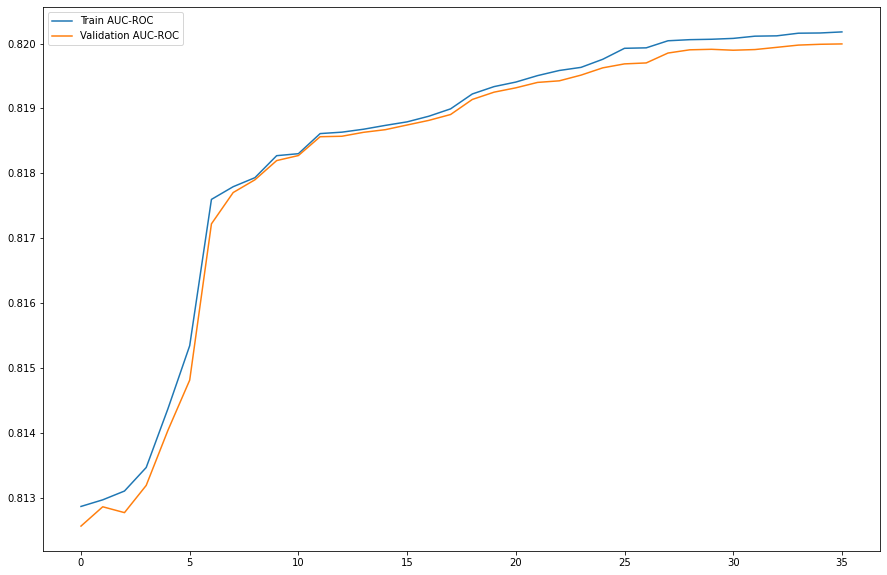

In [63]:
GRB_results.sort_values('Train AUC-ROC')[['Train AUC-ROC', 'Validation AUC-ROC']].reset_index(drop=True).plot(figsize=(15,10))